# Tenge (KZT) exchange rate: results walkthrough

Reads the tables written by `make run_all` (nothing is recomputed here). Run `make run_all` first.

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
T = '../reports/tables/'

## 1. Data quality log (every defect, rows affected)

In [2]:
pd.read_csv('../reports/data_quality_issues.csv')[['issue_id','source','rows_affected','unit','description']]

,issue_id,source,rows_affected,unit,description
0,N00,NBK,280667,rows,"Raw rows downloaded (all currencies, one XML d..."
1,N01,NBK,38,calendar days,Calendar days for which the NBK feed returned ...
2,N02,NBK,0,rows,Non-numeric rate strings
3,N03,NBK,1,rows,"Zero/negative placeholder rates, by currency: ..."
4,N04,NBK,28431,rows,Rates quoted per 10/100/1000/10000 units inste...
5,N05,NBK,0,rows,Rows whose document date differs from the requ...
6,N06,NBK,0,rows,"Duplicate (date, currency) rows"
7,N07,NBK,0,days,"Days where USD, EUR or RUB is missing"
8,N08,NBK,7921,days,Days with a full USD/EUR/RUB triple available ...
9,N09,NBK,3394,days (Sat+Sun+Mon dated),Rate dated T reflects the market of the previo...


## 2. SQL analytics: volatility by year, largest moves, depreciation episodes

In [3]:
display(pd.read_csv(T+'10_volatility_by_year.csv'))
display(pd.read_csv(T+'11_largest_daily_moves.csv').head(10))
display(pd.read_csv(T+'12_devaluation_episodes.csv'))

,year,n_days,usdkzt_vol_ann_pct,rubusd_vol_ann_pct,brent_vol_ann_pct,max_abs_daily_move_pct
0,2005,249,3.26,4.08,32.48,0.77
1,2006,248,4.44,3.88,30.50,1.66
2,2007,246,4.45,3.55,28.86,0.97
3,2008,247,1.13,8.57,50.75,0.23
4,2009,246,17.08,15.88,55.60,16.30
5,2010,246,1.38,9.88,28.59,0.35
6,2011,247,1.73,12.10,27.71,0.42
7,2012,246,1.61,11.65,23.02,0.50
8,2013,244,1.84,8.02,17.34,0.48
9,2014,243,13.25,20.43,19.07,11.84


,market_date,regime,usdkzt_move_pct,rubusd_move_pct,brent_move_pct,span_days
0,2015-08-20,transition,30.38,2.58,-0.26,1
1,2009-02-04,managed,16.30,-0.29,1.22,1
2,2015-08-24,float_1,-14.40,4.27,-5.27,3
3,2014-02-12,managed,11.84,-0.15,-0.54,1
4,2015-09-14,float_1,8.15,-0.39,-2.16,3
5,2020-03-16,shock_2020,6.94,2.90,-14.20,3
6,2022-02-24,shock_2022,6.37,5.83,1.99,1
7,2015-08-26,float_1,5.86,-0.33,-0.24,1
8,2022-02-28,shock_2022,5.80,19.21,4.48,3
9,2014-02-11,managed,5.22,-0.01,-0.88,1


,episode_start,episode_end,trading_days,peak_20d_depreciation_pct,usd_kzt_min,usd_kzt_max
0,2009-02-04,2009-03-03,20,21.5,143.98,150.60
1,2014-02-12,2014-03-12,20,17.6,181.78,184.95
2,2015-08-20,2015-09-17,20,41.1,218.61,283.98
3,2015-09-22,2015-10-08,12,21.1,264.12,274.00
4,2015-11-06,2015-11-24,13,12.8,306.57,312.65
5,2015-12-30,2016-01-19,12,17.0,339.47,379.50
6,2016-01-22,2016-01-28,5,15.3,371.55,379.86
7,2020-03-16,2020-04-09,16,17.3,432.55,448.52
8,2022-02-28,2022-03-28,17,18.2,484.49,512.19


## 3. Regimes

In [4]:
from tenge_fx.regimes import regimes_frame
regimes_frame()

,regime,start_date,end_date,regime_group,rationale
0,managed,2000-01-01,2015-08-19,managed,Managed exchange rate until NBK abandoned the ...
1,transition,2015-08-20,2015-08-20,transition,Day of the float announcement; one-off policy ...
2,float_1,2015-08-21,2020-02-29,float,"Free float, pre-2020 shock."
3,shock_2020,2020-03-01,2020-06-30,float,OPEC+ breakdown and COVID demand collapse.
4,float_2,2020-07-01,2022-02-23,float,Free float between the shocks.
5,shock_2022,2022-02-24,2022-06-30,float,"Invasion of Ukraine, sanctions, ruble collapse..."
6,float_3,2022-07-01,2099-12-31,float,Free float after the 2022 shock.


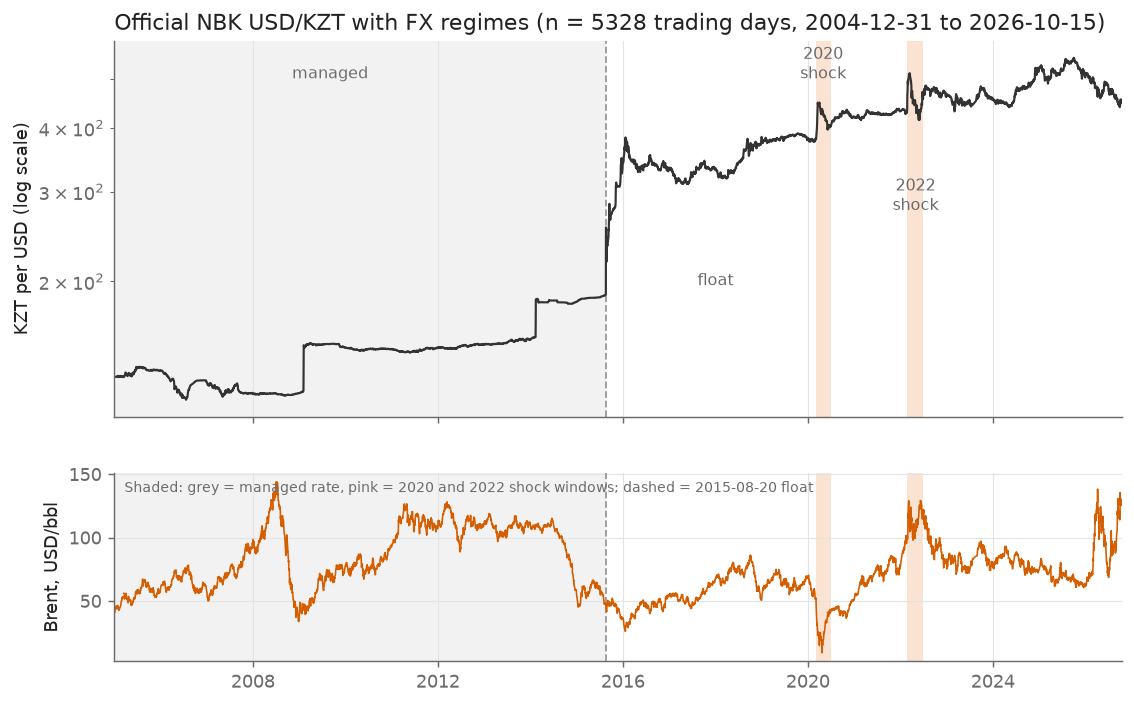

In [5]:
display(Image('../reports/figures/01_usdkzt_regimes.png'))

## 4. Correlations by regime and horizon (block permutation p-values, block bootstrap CI)

In [6]:
c = pd.read_csv(T+'corr_main.csv')
c[['regime','driver','horizon_days','n','start','end','pearson_r','p_perm','p_holm','ci95_low','ci95_high','low_power']].round(3)

,regime,driver,horizon_days,n,start,end,pearson_r,p_perm,p_holm,ci95_low,ci95_high,low_power
0,managed,RUB/USD,1,2605,2005-01-05,2015-08-19,0.019,0.235,1.000,0.005,0.079,False
1,managed,Brent,1,2605,2005-01-05,2015-08-19,-0.002,0.917,1.000,-0.033,0.018,False
2,managed,RUB/USD,5,2587,2005-01-11,2015-08-19,0.086,0.023,0.304,0.046,0.138,False
3,managed,Brent,5,2587,2005-01-11,2015-08-19,0.018,0.586,1.000,-0.048,0.059,False
4,managed,RUB/USD,20,2348,2005-02-01,2015-08-19,0.219,0.013,0.201,0.076,0.359,False
5,managed,Brent,20,2348,2005-02-01,2015-08-19,-0.040,0.533,1.000,-0.148,0.014,False
6,float_1,RUB/USD,1,1106,2015-08-24,2020-02-28,0.248,0.000,0.010,0.219,0.533,False
7,float_1,Brent,1,1106,2015-08-24,2020-02-28,-0.062,0.036,0.403,-0.196,-0.031,False
8,float_1,RUB/USD,5,1098,2015-08-28,2020-02-28,0.411,0.000,0.010,0.269,0.618,False
9,float_1,Brent,5,1098,2015-08-28,2020-02-28,-0.312,0.000,0.010,-0.451,-0.223,False


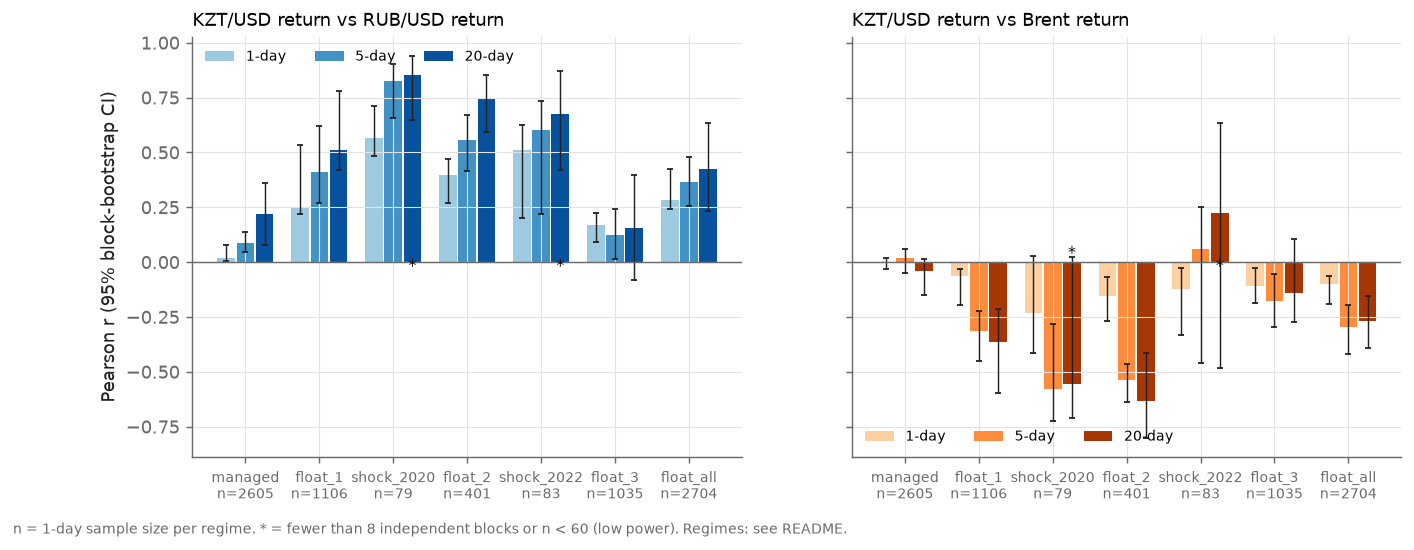

In [7]:
display(Image('../reports/figures/03_correlation_by_regime_horizon.png'))

## 5. Robustness

In [8]:
v = pd.read_csv(T+'robust_variants.csv')
v[(v.regime=='float_all')&(v.horizon_days==5)][['variant','driver','n','pearson_r','p_perm','ci95_low','ci95_high']].round(3)

,variant,driver,n,pearson_r,p_perm,ci95_low,ci95_high
20,baseline,RUB/USD,2666,0.367,0.0,0.248,0.488
21,baseline,Brent,2666,-0.298,0.0,-0.422,-0.192
22,drop top 1% |RUB| days,RUB/USD,2639,0.303,0.0,0.204,0.413
23,drop top 1% |RUB| days,Brent,2639,-0.314,0.0,-0.427,-0.217
24,drop top 5% |RUB| days,RUB/USD,2532,0.311,0.0,0.212,0.416
25,drop top 5% |RUB| days,Brent,2532,-0.273,0.0,-0.351,-0.208
26,drop |RUB| > 3 robust sigma,RUB/USD,2537,0.313,0.0,0.214,0.421
27,drop |RUB| > 3 robust sigma,Brent,2537,-0.273,0.0,-0.347,-0.208
28,drop top 1% |KZT| days,RUB/USD,2639,0.380,0.0,0.279,0.470
29,drop top 1% |KZT| days,Brent,2639,-0.270,0.0,-0.340,-0.204


In [9]:
display(pd.read_csv(T+'regressions_hac.csv').query('horizon_days==5 and regime=="float_all"').round(3))
display(pd.read_csv(T+'regression_brent_lead.csv').round(3))

,regime,horizon_days,model,term,n,start,end,beta_std,t_hac,p_hac,r2,hac_lags
44,float_all,5,Brent only,Brent,2666,2015-08-28,2026-10-15,-0.298,-4.561,0.0,0.089,10
45,float_all,5,RUB only,RUB/USD,2666,2015-08-28,2026-10-15,0.367,6.403,0.0,0.135,10
46,float_all,5,RUB + Brent,RUB/USD,2666,2015-08-28,2026-10-15,0.332,6.721,0.0,0.197,10
47,float_all,5,RUB + Brent,Brent,2666,2015-08-28,2026-10-15,-0.251,-4.747,0.0,0.197,10


,regime,term,n,beta_std,t_hac,p_hac,r2
0,float_all,r_rub,2699,0.318,9.174,0.000,0.146
1,float_all,r_brent,2699,-0.084,-2.886,0.004,0.146
2,float_all,r_brent_l1,2699,-0.161,-6.330,0.000,0.146


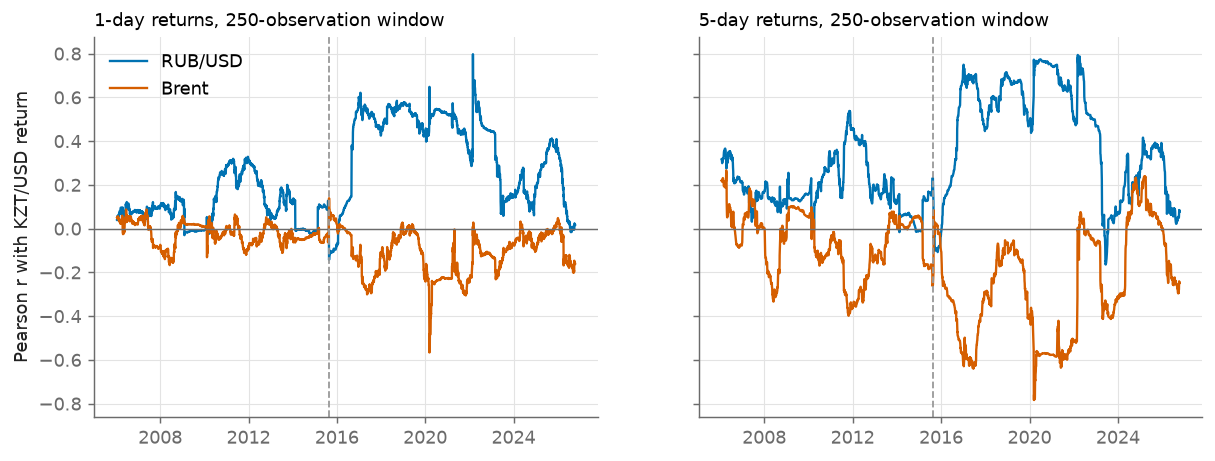

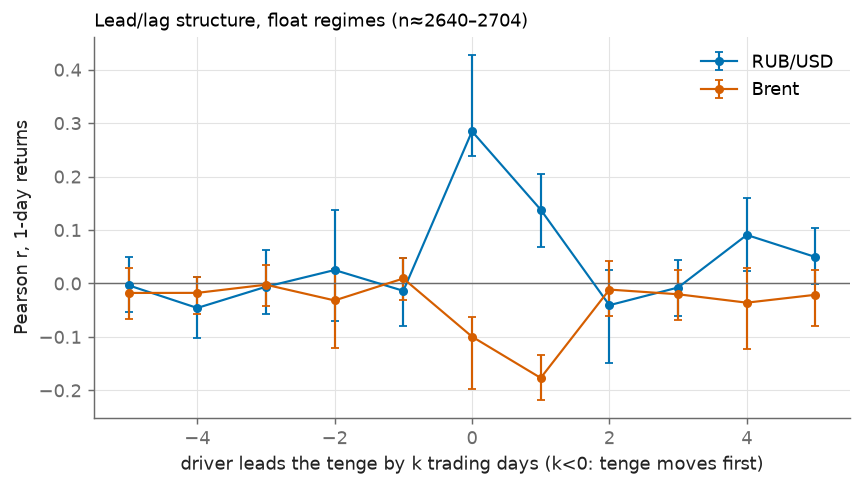

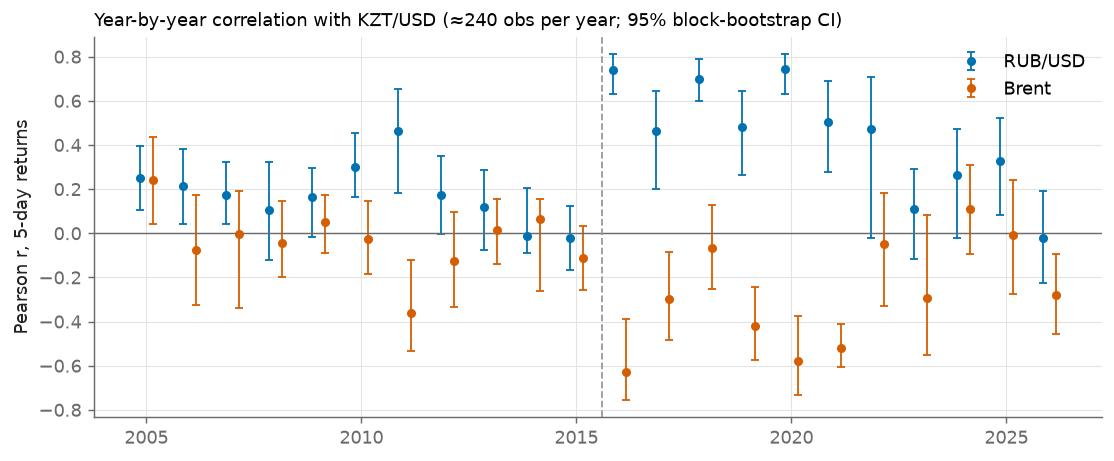

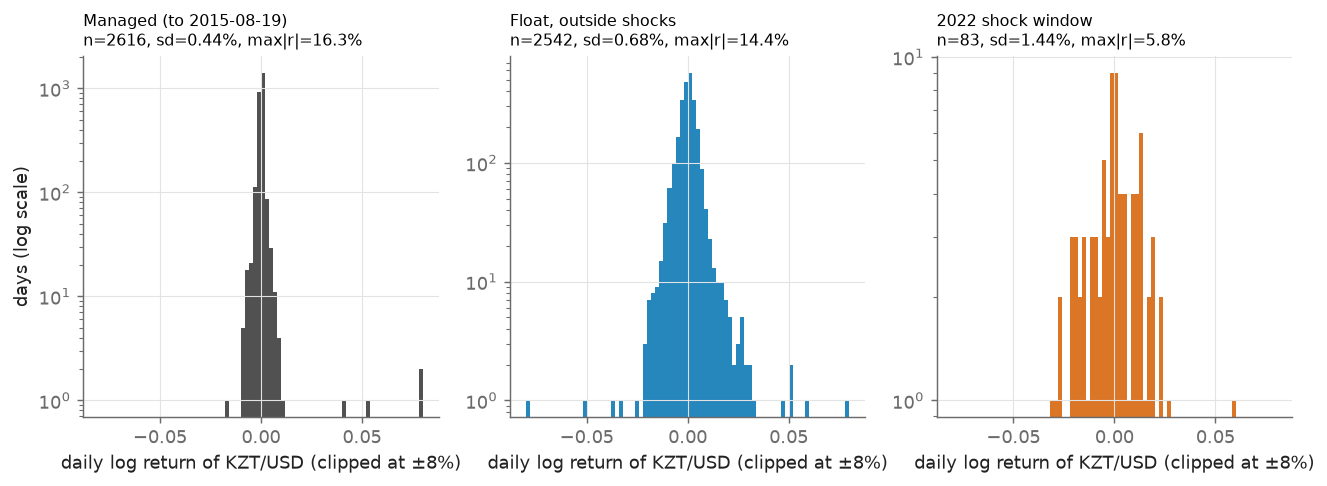

In [10]:
for f in ['02_rolling_correlation','05_lead_lag','06_correlation_by_year','04_return_distributions']:
    display(Image(f'../reports/figures/{f}.png'))